# SHAPformer with two weeks of input and a two-day forecast

This notebook follows `training_dataframe.ipynb` on the TransnetBW load data, but with other window lengths:

- **input length**: two weeks (336 hours) of past information, including the target,
- **horizon**: two days (48 hours) to forecast.

The past load is explained in groups ("periods") of 24 hours, the default `period_length`, so there are 14 periods instead of 7.
Together with the 6 covariates, these are 20 feature groups. The exact method would need 2<sup>20</sup> ≈ 1 million
model evaluations per explanation, so all explanations here use `method="permutation"`.

Steps:

1. load the data and set up a SHAPformer model with `input_length=336` and `horizon=48`,
2. train the model for at most 100 epochs with early stopping (or load a trained one),
3. evaluate the forecast errors on the validation year 2019,
4. forecast and explain two days,
5. create dependence plots from many explanations.

The switch `TRAINING` decides whether the model is trained from scratch and saved to `MODEL_PATH` (`True`), or whether the trained model is loaded from `MODEL_PATH` (`False`).

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt

from pathlib import Path

import shapformer
from shapformer import SHAPformer

print(f"shapformer {shapformer.__version__} from {shapformer.__file__}")

REPO_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = REPO_DIR / "data"  # the datasets (see the README)
MODEL_DIR = REPO_DIR / "models"  # the trained models

TRAINING = False  # True: train the model from scratch and save it to MODEL_PATH; False: load the trained model from MODEL_PATH
MODEL_PATH = MODEL_DIR / "model_two_weeks_two_days.ckpt"

INPUT_LENGTH = 14 * 24  # two weeks of past information
HORIZON = 2 * 24  # two days to forecast

## Load the data

The same data as in `training_dataframe.ipynb`: one row per hour (2015–2019), indexed by the local timestamp, with the target `load` (in MW) and the covariates `hour_of_day`, `day_of_week`, `month`, `holiday`, `temperature` and `precipitation`.

In [2]:
file = DATA_DIR / "transnet" / "transnet_bw_hourly.csv"
df = pd.read_csv(file, parse_dates=[0], index_col=0)
df = df.drop(columns="irradiance")
df["month"] -= 1  # categorical features must start at 0
print(df)

                                load  hour_of_day  day_of_week  month  \
cet_cest_timestamp                                                      
2015-01-01 01:00:00+01:00  5279.7900            1            3      0   
2015-01-01 02:00:00+01:00  5024.5425            2            3      0   
2015-01-01 03:00:00+01:00  4879.9750            3            3      0   
2015-01-01 04:00:00+01:00  4858.5250            4            3      0   
2015-01-01 05:00:00+01:00  4600.1400            5            3      0   
...                              ...          ...          ...    ...   
2019-12-31 19:00:00+01:00  5914.4275           19            1     11   
2019-12-31 20:00:00+01:00  5620.2250           20            1     11   
2019-12-31 21:00:00+01:00  5517.5050           21            1     11   
2019-12-31 22:00:00+01:00  5487.2600           22            1     11   
2019-12-31 23:00:00+01:00  5293.9675           23            1     11   

                           holiday  temperature  p

## Create the model

The same small transformer as in `training_dataframe.ipynb` (one layer, four attention heads, hidden dimension 128), with the window lengths set by `input_length` and `horizon`. `input_length` must be a multiple of 24, since the past target is explained in groups of 24 time steps.

In [3]:
model = SHAPformer(
    target="load",
    feature_categories={
        "hour_of_day": 24,
        "day_of_week": 7,
        "month": 12,
        "holiday": 2,
        "temperature": None,
        "precipitation": None
    },
    d_model=128,
    n_layers=1,
    n_heads=4,
    input_length=INPUT_LENGTH,
    horizon=HORIZON
)
print(f"input length {model.get_input_length()}, horizon {model.get_horizon()}, {model.get_n_periods()} past-day groups")

input length 336, horizon 48, 14 past-day groups


## Train the model (or load a trained model)

As in `training_dataframe.ipynb`, all rows before `VALIDATION_START` are used for training and the rows from there on for validation. Each sample is now two weeks of past information and the following two days of covariates. Training runs for at most 100 epochs and stops early when the validation loss has not improved for 10 epochs; the model with the lowest validation loss is restored.

In [4]:
DEVICE = "cuda"
VALIDATION_START = "2019-01-01"
EPOCHS = 100

if TRAINING:
    model.to(DEVICE)
    model = model.fit(df, VALIDATION_START, epochs=EPOCHS, batch_size=128, patience=10)
    MODEL_DIR.mkdir(exist_ok=True)
    torch.save(model, MODEL_PATH)
else:
    model = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
    model.eval()

  0%|          | 0/271 [00:00<?, ?it/s]

  0%|          | 1/271 [00:00<02:33,  1.76it/s]

  1%|          | 2/271 [00:00<01:19,  3.38it/s]

  1%|          | 3/271 [00:00<00:56,  4.78it/s]

  1%|▏         | 4/271 [00:00<00:45,  5.93it/s]

  2%|▏         | 5/271 [00:00<00:38,  6.84it/s]

... (9,804 outputs left out)

100%|█████████▉| 270/271 [00:27<00:00,  9.22it/s]

100%|██████████| 271/271 [00:27<00:00,  9.33it/s]

100%|██████████| 271/271 [00:27<00:00,  9.71it/s]

Epoch 36/100, Training loss: 0.08603166858923392, Validation loss: 0.026765119657262516 (best: 0.025235107088165617), Epochs without improvement: 10/10
Early stopping.
Restored the model from epoch 26 with validation loss 0.025235107088165617.


## Evaluate the forecasts

We forecast from every hour of the validation year 2019 (each forecast with the full two weeks of input before it, and all 48 forecasted hours in the data), and compute the mean absolute error (MAE), the root mean squared error (RMSE) and the mean absolute percentage error (MAPE).

As a reference, the seasonal naive forecast repeats the load of one week earlier, which is part of the two-week input.

In [5]:
timestamps = pd.to_datetime(df.index, utc=True)
first_validation_start = int((timestamps < pd.Timestamp(VALIDATION_START, tz="UTC")).sum())
evaluation_starts = list(range(first_validation_start, len(df) - HORIZON + 1))

load = df["load"].to_numpy()
future_covariates = df.drop(columns="load")
predictions = np.stack([
    model.predict(df.iloc[s - INPUT_LENGTH:s], future_covariates.iloc[s:s + HORIZON]).to_numpy()
    for s in evaluation_starts
])
actuals = np.stack([load[s:s + HORIZON] for s in evaluation_starts])
naive = np.stack([load[s - 168:s - 168 + HORIZON] for s in evaluation_starts])
print(f"{len(evaluation_starts)} forecasts of {HORIZON} hours")


def errors(forecasts):
    error = forecasts - actuals
    return {
        "MAE [MW]": np.abs(error).mean(),
        "RMSE [MW]": np.sqrt((error ** 2).mean()),
        "MAPE [%]": 100 * np.abs(error / actuals).mean()
    }


pd.DataFrame({"SHAPformer": errors(predictions), "seasonal naive (one week earlier)": errors(naive)}).T.round(2)

8712 forecasts of 48 hours


,MAE [MW],RMSE [MW],MAPE [%]
SHAPformer,192.19,246.62,2.91
seasonal naive (one week earlier),457.29,774.15,7.02


The error per forecasted hour: the error grows with the distance to the forecast start.

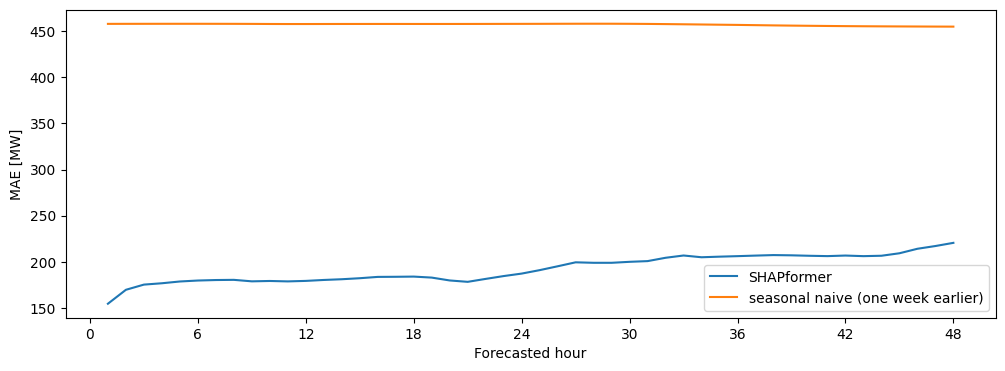

In [6]:
steps = np.arange(1, HORIZON + 1)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(steps, np.abs(predictions - actuals).mean(axis=0), label="SHAPformer")
ax.plot(steps, np.abs(naive - actuals).mean(axis=0), label="seasonal naive (one week earlier)")
ax.set_xticks(range(0, HORIZON + 1, 6))
ax.set_xlabel("Forecasted hour")
ax.set_ylabel("MAE [MW]")
ax.legend()
plt.show()

## Forecast two days

`model.predict(past, future)` takes the last 336 hours before the forecast (with the target and all covariates) as `past`, and the 48 hours to forecast (with the covariates only) as `future`. Here, we forecast Monday and Tuesday, 15 and 16 April 2019, and compare the forecast with the actual load.

<Axes: xlabel='cet_cest_timestamp'>

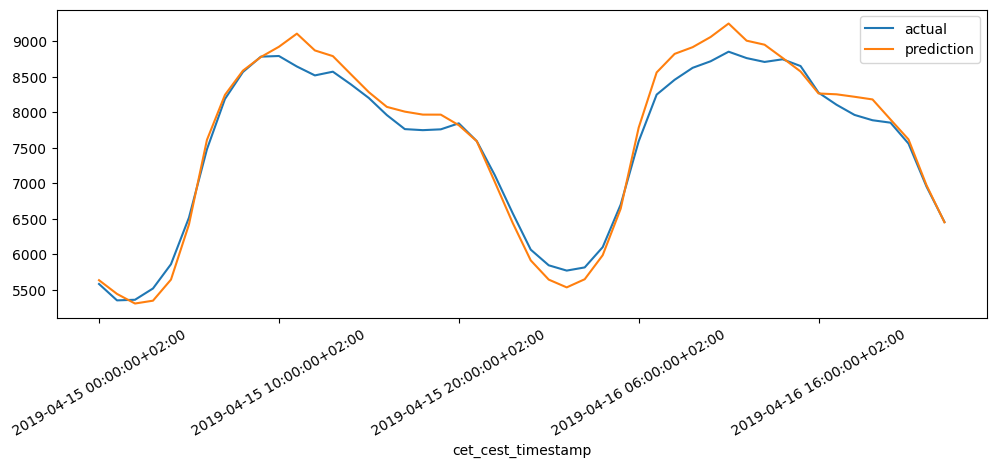

In [7]:
FORECAST_START = "2019-04-15 00:00:00+02:00"

start = df.index.get_loc(FORECAST_START)
past = df.iloc[start - INPUT_LENGTH:start]
future = df.iloc[start:start + HORIZON].drop(columns="load")

prediction = model.predict(past, future)

actual = df["load"].iloc[start:start + HORIZON]
comparison = pd.DataFrame({"actual": actual, "prediction": prediction})
comparison.plot(figsize=(12, 4), rot=30)

## Explain the forecast

`model.explain(past, future, method="permutation")` splits the forecast into contributions of the feature groups: one group per covariate, and one group per day of the past load (`period 1` is the oldest day, `period 14` the most recent one). As before, `base` + the sum of all `shap_values` = `prediction`, and the values are Owen values with the past load periods as one group.

The permutation method approximates the Owen values with `n_permutations` random orders of the feature groups (with the periods kept together). With 20 feature groups, each permutation needs 2 · 20 + 1 = 41 model evaluations.

In [8]:
from shapformer import plot_explanation

SEED = 42
N_PERMUTATIONS = 10  # permutations per explanation

explanation = model.explain(past, future, method="permutation", n_permutations=N_PERMUTATIONS, seed=SEED)
print("max. |base + sum of SHAP values - prediction|:",
      (explanation["base"] + explanation["shap_values"].sum(axis=1) - explanation["prediction"]).abs().max())

  0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 4/4 [00:00<00:00, 162.66it/s]

max. |base + sum of SHAP values - prediction|: 4.1640309063950554e-05


The explanation as a stacked area chart around the base value (dotted). With `mode="load"`, the 14 periods are summed into one group; with `mode="periods"`, the covariates are summed into one group, so the contributions of the single days become visible.

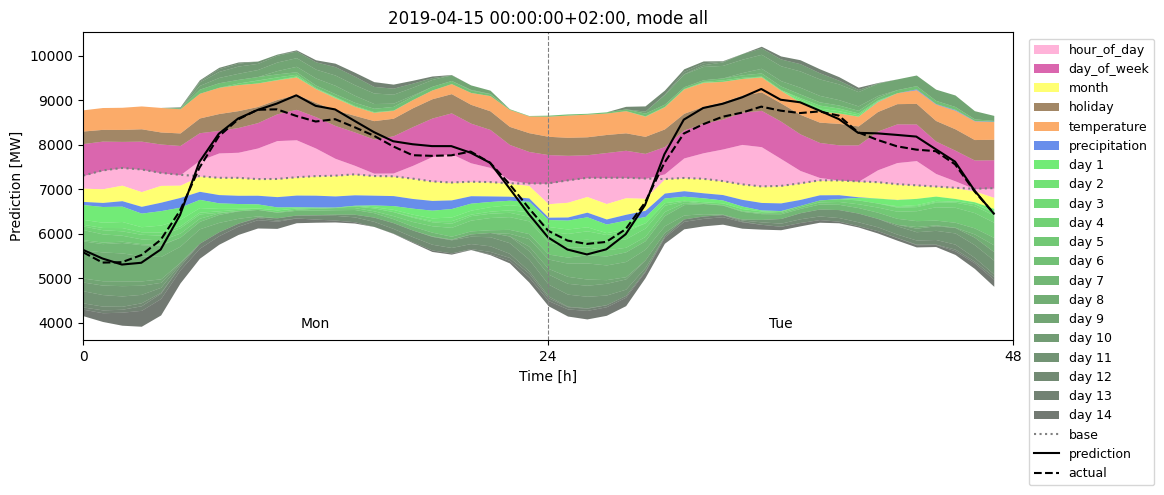

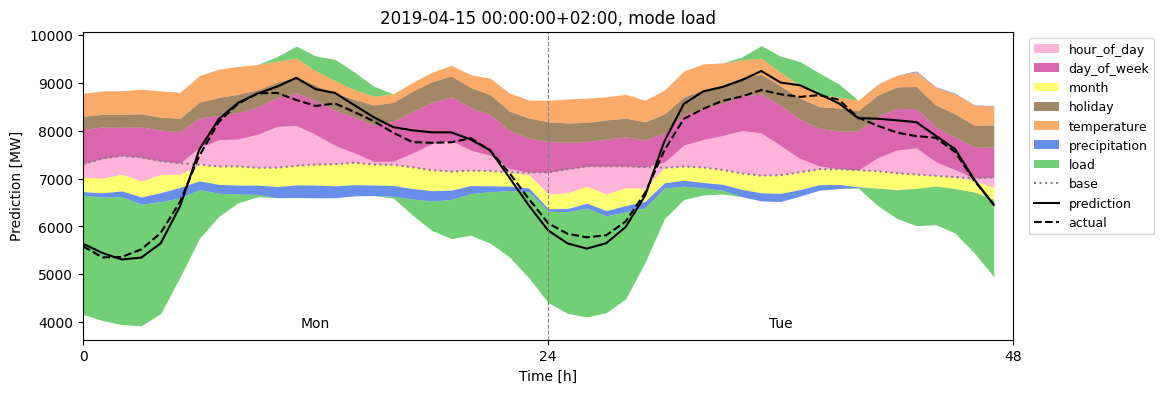

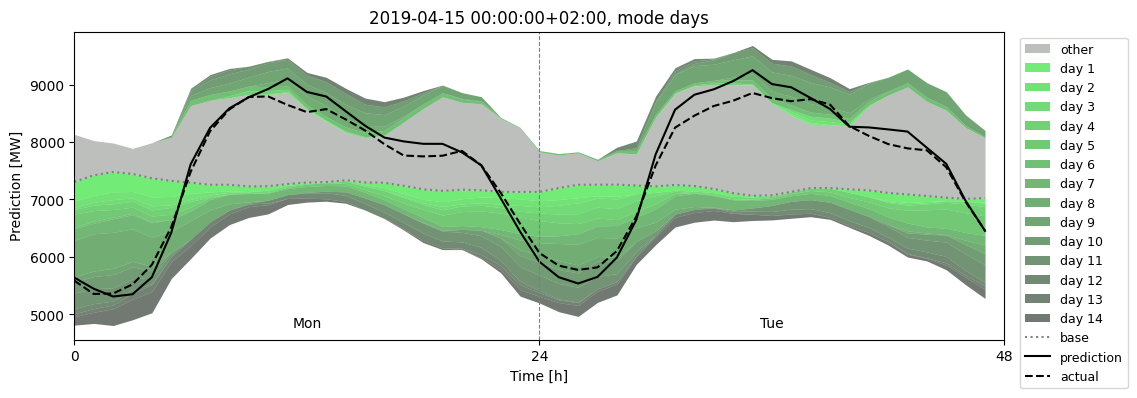

In [9]:
for mode in ("all", "load", "periods"):
    plot_explanation(explanation, mode=mode, actual=actual, title=f"{FORECAST_START}, mode {mode}")
    plt.show()

## Dependence plots of many explanations

As in `training_dataframe.ipynb`: each dot is one explained forecast, with the feature value on the x-axis and its SHAP value at the forecasted hour `DEPENDENCE_HORIZON` (here the 24th hour) on the y-axis. For the load, the x-axis is the load one week before that hour (which is in the two-week input), and the y-axis the sum of the contributions of all 14 periods.

We explain 1000 random forecast starts in the validation period with `method="permutation"`.

0.129 s per explanation on average


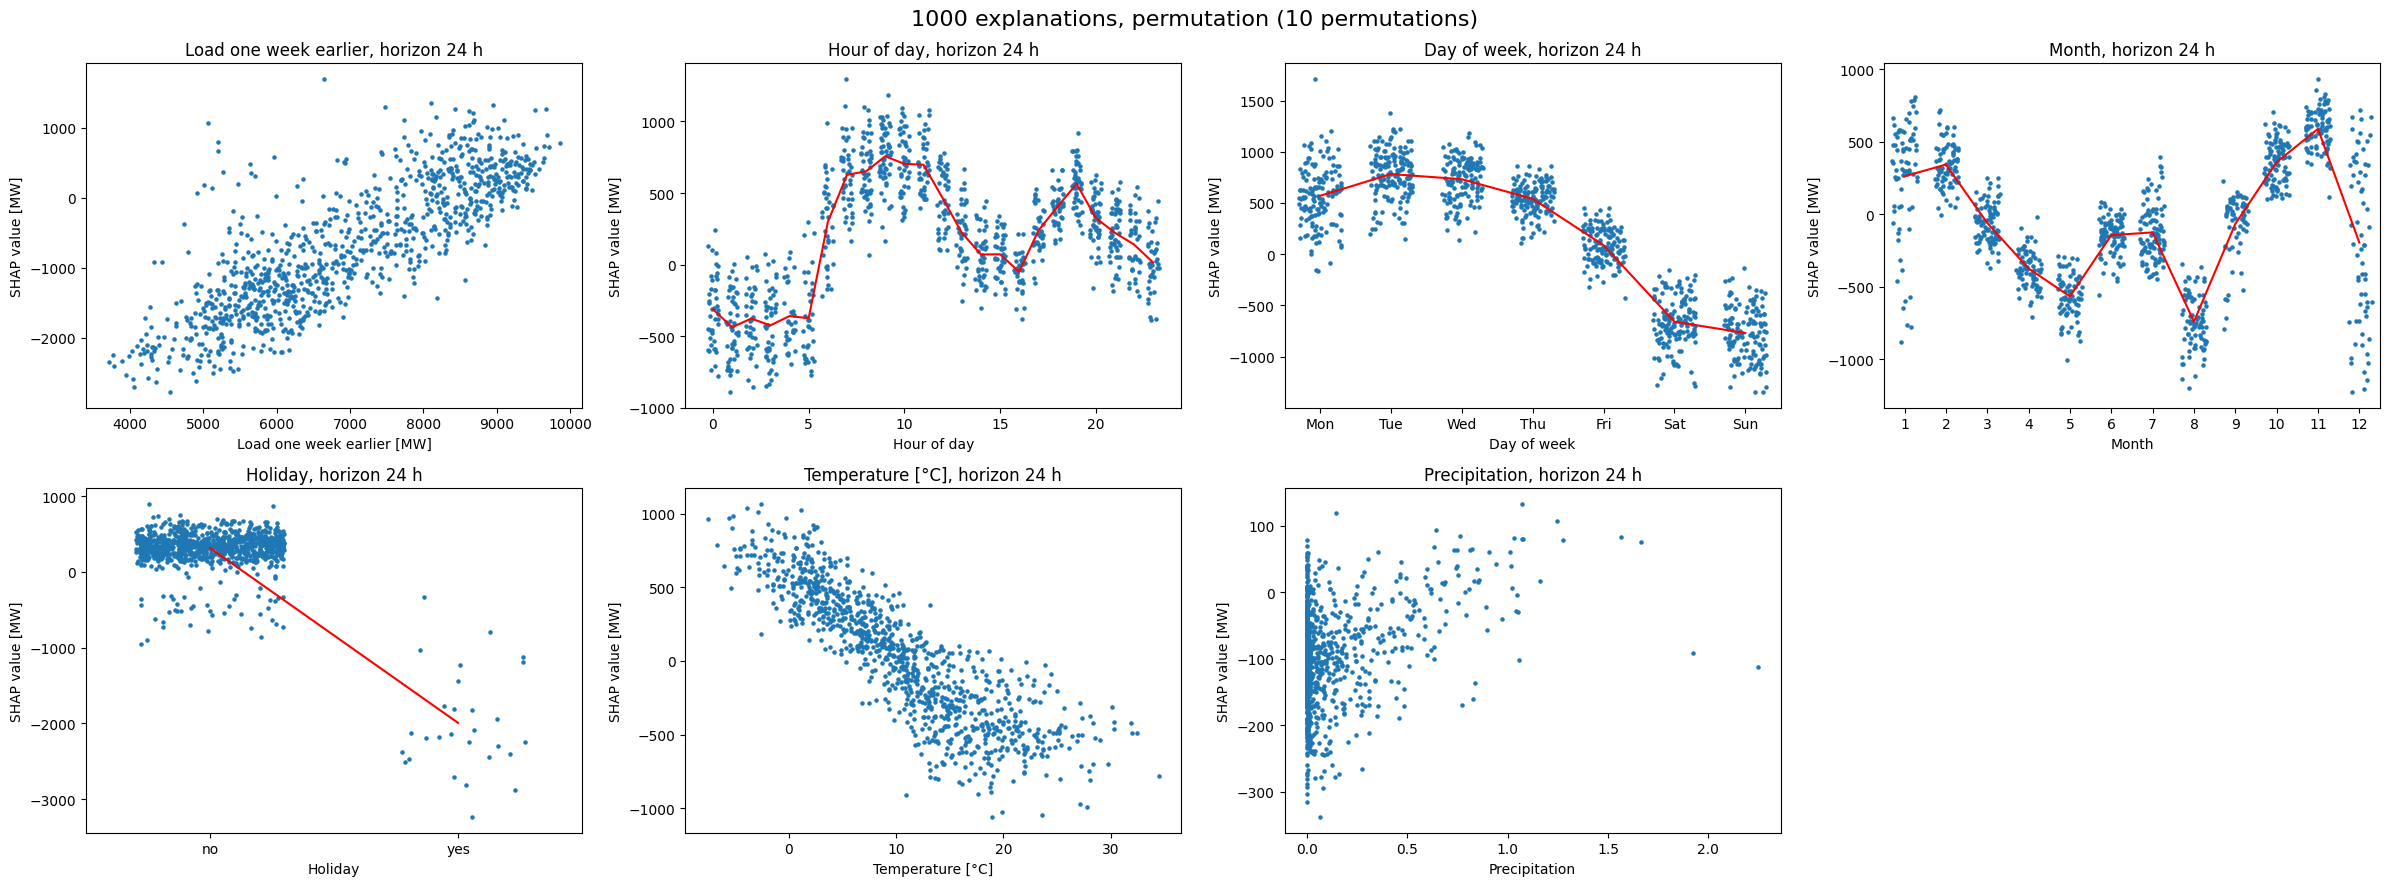

In [10]:
import math
import random
import time
from shapformer import plot_dependence

DEPENDENCE_HORIZON = 24  # plot the SHAP values of the 24th predicted hour; None plots all 48 hours
N_COLUMNS = 4

starts_1000 = random.Random(SEED).sample(evaluation_starts, 1000)

start_time = time.perf_counter()
explanations = [
    model.explain(df.iloc[s - INPUT_LENGTH:s], future_covariates.iloc[s:s + HORIZON], method="permutation",
                  n_permutations=N_PERMUTATIONS, seed=SEED + i, progress=False)
    for i, s in enumerate(starts_1000)
]
print(f"{(time.perf_counter() - start_time) / len(explanations):.3f} s per explanation on average")

n_rows = math.ceil(len(model.feature_names) / N_COLUMNS)
fig, axs = plt.subplots(n_rows, N_COLUMNS, figsize=(6 * N_COLUMNS, 4.5 * n_rows))
for ax, feature in zip(axs.flat, model.feature_names):
    plot_dependence(explanations, feature, horizon=DEPENDENCE_HORIZON, ax=ax)
for ax in axs.flat[len(model.feature_names):]:
    ax.set_visible(False)
fig.suptitle(f"1000 explanations, permutation ({N_PERMUTATIONS} permutations)", fontsize=16)
fig.tight_layout()
plt.show()

The mean absolute contribution of each feature group over the 1000 explanations and all 48 forecasted hours shows how much the model relies on each covariate and on each of the 14 periods (days) of the past load.

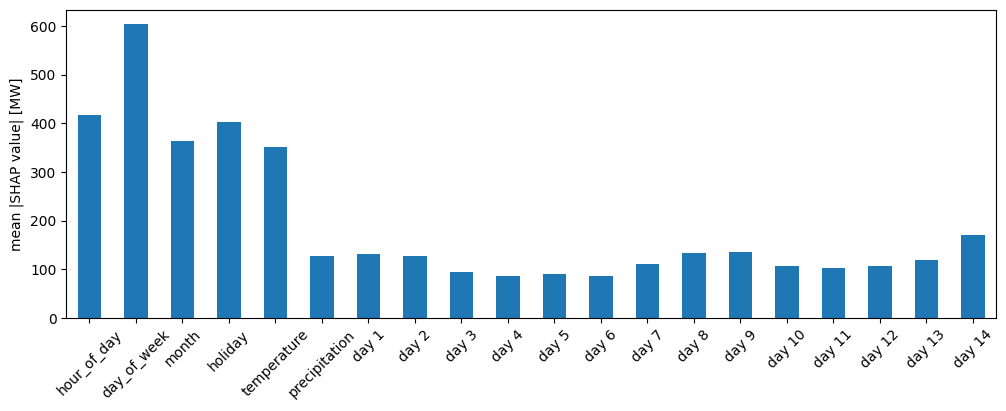

In [11]:
mean_abs = pd.concat([e["shap_values"].abs().mean() for e in explanations], axis=1).mean(axis=1)
ax = mean_abs.plot.bar(figsize=(12, 4), rot=45)
ax.set_ylabel("mean |SHAP value| [MW]")
plt.show()